# Heart Disease Prediction using Machine Learning
#### A machine learning project that predicts the presence of heart disease from patient health and clinical measurements using Python and Logistic Regression.

In [95]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns 


## Objectives


#### To analyze the heart disease dataset and understand the patient health-related information.
#### To perform data cleaning and preprocessing to prepare the dataset for machine learning.

#### To explore the relationship between different health factors such as Age, Cholesterol, Resting Blood Pressure, Maximum Heart Rate and Heart Disease.

####  To identify important features that may influence heart disease prediction.

#### To apply suitable classification algorithms to predict the presence or absence of heart disease.

#### To evaluate the model performance using appropriate classification metrics.

####  To identify useful patterns and insights from the dataset that can support better understanding of heart disease-related factors.

## Load the dataset

In [96]:
hr=pd.read_csv(r"C:\Users\user\Downloads\heart.csv")

In [97]:
hr

,Age,Sex,ChestPainType,RestingBP,Cholesterol,FastingBS,RestingECG,MaxHR,ExerciseAngina,Oldpeak,ST_Slope,HeartDisease
0,40,M,ATA,140,289,0,Normal,172,N,0.0,Up,0
1,49,F,NAP,160,180,0,Normal,156,N,1.0,Flat,1
2,37,M,ATA,130,283,0,ST,98,N,0.0,Up,0
3,48,F,ASY,138,214,0,Normal,108,Y,1.5,Flat,1
4,54,M,NAP,150,195,0,Normal,122,N,0.0,Up,0
...,...,...,...,...,...,...,...,...,...,...,...,...
913,45,M,TA,110,264,0,Normal,132,N,1.2,Flat,1
914,68,M,ASY,144,193,1,Normal,141,N,3.4,Flat,1
915,57,M,ASY,130,131,0,Normal,115,Y,1.2,Flat,1
916,57,F,ATA,130,236,0,LVH,174,N,0.0,Flat,1


## Data Undestanding

In [98]:
hr.shape

(918, 12)

In [99]:
hr.size

11016

In [100]:
hr.head()

,Age,Sex,ChestPainType,RestingBP,Cholesterol,FastingBS,RestingECG,MaxHR,ExerciseAngina,Oldpeak,ST_Slope,HeartDisease
0,40,M,ATA,140,289,0,Normal,172,N,0.0,Up,0
1,49,F,NAP,160,180,0,Normal,156,N,1.0,Flat,1
2,37,M,ATA,130,283,0,ST,98,N,0.0,Up,0
3,48,F,ASY,138,214,0,Normal,108,Y,1.5,Flat,1
4,54,M,NAP,150,195,0,Normal,122,N,0.0,Up,0


In [101]:
hr.tail()

,Age,Sex,ChestPainType,RestingBP,Cholesterol,FastingBS,RestingECG,MaxHR,ExerciseAngina,Oldpeak,ST_Slope,HeartDisease
913,45,M,TA,110,264,0,Normal,132,N,1.2,Flat,1
914,68,M,ASY,144,193,1,Normal,141,N,3.4,Flat,1
915,57,M,ASY,130,131,0,Normal,115,Y,1.2,Flat,1
916,57,F,ATA,130,236,0,LVH,174,N,0.0,Flat,1
917,38,M,NAP,138,175,0,Normal,173,N,0.0,Up,0


In [102]:
hr.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 918 entries, 0 to 917
Data columns (total 12 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Age             918 non-null    int64  
 1   Sex             918 non-null    object 
 2   ChestPainType   918 non-null    object 
 3   RestingBP       918 non-null    int64  
 4   Cholesterol     918 non-null    int64  
 5   FastingBS       918 non-null    int64  
 6   RestingECG      918 non-null    object 
 7   MaxHR           918 non-null    int64  
 8   ExerciseAngina  918 non-null    object 
 9   Oldpeak         918 non-null    float64
 10  ST_Slope        918 non-null    object 
 11  HeartDisease    918 non-null    int64  
dtypes: float64(1), int64(6), object(5)
memory usage: 86.2+ KB


In [103]:
hr.dtypes

Age                 int64
Sex                object
ChestPainType      object
RestingBP           int64
Cholesterol         int64
FastingBS           int64
RestingECG         object
MaxHR               int64
ExerciseAngina     object
Oldpeak           float64
ST_Slope           object
HeartDisease        int64
dtype: object

In [104]:
hr.columns

Index(['Age', 'Sex', 'ChestPainType', 'RestingBP', 'Cholesterol', 'FastingBS',
       'RestingECG', 'MaxHR', 'ExerciseAngina', 'Oldpeak', 'ST_Slope',
       'HeartDisease'],
      dtype='object')

In [105]:
hr.describe()

,Age,RestingBP,Cholesterol,FastingBS,MaxHR,Oldpeak,HeartDisease
count,918.000000,918.000000,918.000000,918.000000,918.000000,918.000000,918.000000
mean,53.510893,132.396514,198.799564,0.233115,136.809368,0.887364,0.553377
std,9.432617,18.514154,109.384145,0.423046,25.460334,1.066570,0.497414
min,28.000000,0.000000,0.000000,0.000000,60.000000,-2.600000,0.000000
25%,47.000000,120.000000,173.250000,0.000000,120.000000,0.000000,0.000000
50%,54.000000,130.000000,223.000000,0.000000,138.000000,0.600000,1.000000
75%,60.000000,140.000000,267.000000,0.000000,156.000000,1.500000,1.000000
max,77.000000,200.000000,603.000000,1.000000,202.000000,6.200000,1.000000


##### The dataset contains 918 records with no missing values in the numerical columns.

##### The average patient age is 53.51 years, with values ranging from 28 to 77 years.
     
##### The average recorded blood pressure is 132.40, with values ranging from 0 to 200.
     
##### The average cholesterol level is 198.80, ranging from 0 to 603.
     
##### The average fasting blood sugar value is 0.23.

##### The average maximum heart rate is 136.81, ranging from 60 to 202.

##### The average Oldpeak value is 0.89, with values ranging from -2.6 to 6.2.

##### The target variable has an average value of 0.55, indicating that approximately 55.34% of the records belong to class 1.

## DATA CLEANING

In [106]:
hr.duplicated().sum()

np.int64(0)

In [107]:
hr.isnull().sum()

Age               0
Sex               0
ChestPainType     0
RestingBP         0
Cholesterol       0
FastingBS         0
RestingECG        0
MaxHR             0
ExerciseAngina    0
Oldpeak           0
ST_Slope          0
HeartDisease      0
dtype: int64

##### There are no missing values or duplicate records in the dataset.

## EDA & DATA VISUALIZATION

## 1.Heart Disease Distribution
To identify the number of patients with and without heart disease.

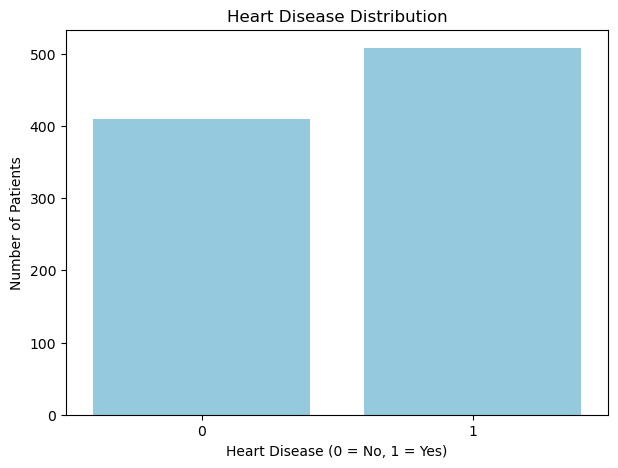

In [108]:
plt.figure(figsize=(7, 5))

sns.countplot(data=hr, x='HeartDisease',color="skyblue")

plt.title('Heart Disease Distribution')
plt.xlabel('Heart Disease (0 = No, 1 = Yes)')
plt.ylabel('Number of Patients')

plt.show()

#### The graph shows that out of all the patients, around 490 have heart disease, while around 410 do not have heart disease. So, the number of patients with heart disease is higher.

### 2. Age vs Heart Disease
To analyze the distribution of patients' ages and understand how age varies between patients with and without heart disease.

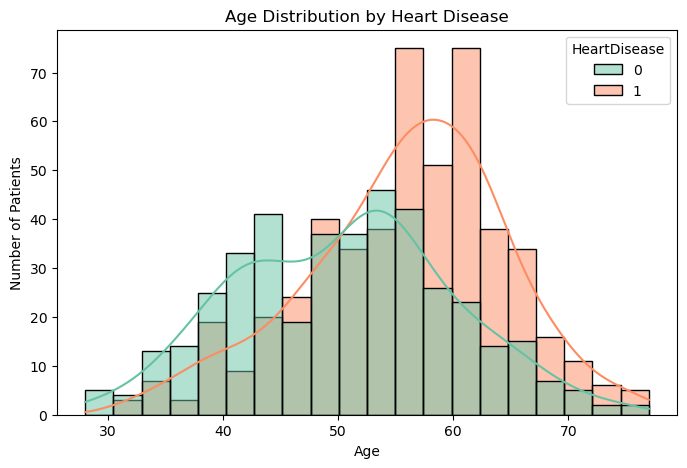

In [109]:
plt.figure(figsize=(8, 5))

sns.histplot(data=hr, x='Age', hue='HeartDisease',
             kde=True, bins=20, palette='Set2')

plt.title('Age Distribution by Heart Disease')
plt.xlabel('Age')
plt.ylabel('Number of Patients')

plt.show()

#####  The graph shows that most patients with heart disease are between 55 and 65 years old. Patients without heart disease are more commonly seen between 40 and 55 years old. This suggests that heart disease is more common among older patients in this dataset.

### 3. Chest Pain Type vs Heart Disease 
To understand which chest pain types are more commonly associated with heart disease in the dataset.

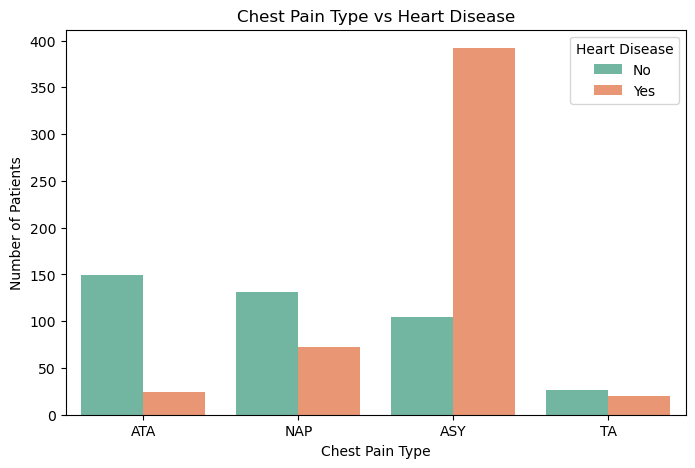

In [110]:
plt.figure(figsize=(8, 5))

sns.countplot(data=hr, x='ChestPainType', hue='HeartDisease',
              palette='Set2')

plt.title('Chest Pain Type vs Heart Disease')
plt.xlabel('Chest Pain Type')
plt.ylabel('Number of Patients')
plt.legend(title='Heart Disease', labels=['No', 'Yes'])

plt.show()

##### The graph shows that patients with heart disease are mostly found in the ASY (Asymptomatic) category, while patients without heart disease are higher in the ATA and NAP categories. The TA category has fewer patients in both groups.

### 4. Cholesterol Distribution by Heart Disease
To understand the differences in cholesterol levels between the two groups and identify outliers.

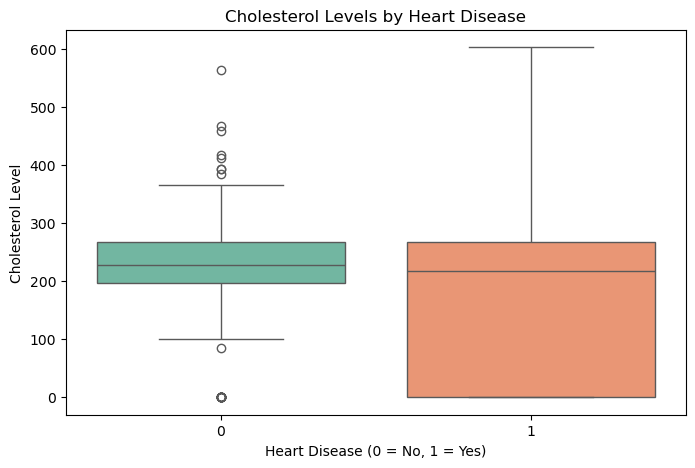

In [111]:
plt.figure(figsize=(8, 5))

sns.boxplot(data=hr, x='HeartDisease', y='Cholesterol',
            hue='HeartDisease', palette='Set2', legend=False)

plt.title('Cholesterol Levels by Heart Disease')
plt.xlabel('Heart Disease (0 = No, 1 = Yes)')
plt.ylabel('Cholesterol Level')

plt.show()

#### The meadian cholesterol level is  aound 225 for patients without heart disease and 220 for patients with heart desease

### 5. Correlation Heatmap 
To identify numerical features that have stronger positive or negative relationships with heart disease.

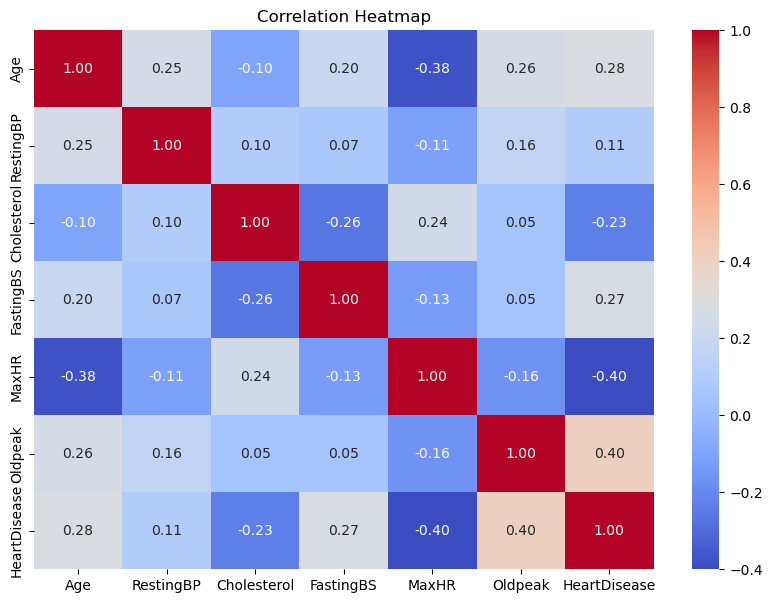

In [112]:
plt.figure(figsize=(10, 7))

sns.heatmap(hr.select_dtypes(include='number').corr(),
            annot=True, cmap='coolwarm', fmt='.2f')

plt.title('Correlation Heatmap')

plt.show()

##### The heatmap shows that Oldpeak and Age have a positive correlation with Heart Disease. MaxHR has a negative correlation, while Cholesterol has a weak negative correlation. This indicates that these features have different levels of association with heart disease.

## Feature and Target Separation

In [113]:
X= hr.drop('HeartDisease', axis=1)

Y= hr['HeartDisease']

In [114]:
x

,Age,Sex,ChestPainType,RestingBP,Cholesterol,FastingBS,RestingECG,MaxHR,ExerciseAngina,Oldpeak,ST_Slope
0,40,M,ATA,140,289,0,Normal,172,N,0.0,Up
1,49,F,NAP,160,180,0,Normal,156,N,1.0,Flat
2,37,M,ATA,130,283,0,ST,98,N,0.0,Up
3,48,F,ASY,138,214,0,Normal,108,Y,1.5,Flat
4,54,M,NAP,150,195,0,Normal,122,N,0.0,Up
...,...,...,...,...,...,...,...,...,...,...,...
913,45,M,TA,110,264,0,Normal,132,N,1.2,Flat
914,68,M,ASY,144,193,1,Normal,141,N,3.4,Flat
915,57,M,ASY,130,131,0,Normal,115,Y,1.2,Flat
916,57,F,ATA,130,236,0,LVH,174,N,0.0,Flat


In [115]:
Y

0      0
1      1
2      0
3      1
4      0
      ..
913    1
914    1
915    1
916    1
917    0
Name: HeartDisease, Length: 918, dtype: int64

## Encoding

In [116]:
categorical_cols=x.select_dtypes(include="object").columns
print(categorical_cols)

Index(['Sex', 'ChestPainType', 'RestingECG', 'ExerciseAngina', 'ST_Slope'], dtype='object')


In [117]:
X=pd.get_dummies(x,columns=categorical_cols,drop_first=True)

In [118]:
X

,Age,RestingBP,Cholesterol,FastingBS,MaxHR,Oldpeak,Sex_M,ChestPainType_ATA,ChestPainType_NAP,ChestPainType_TA,RestingECG_Normal,RestingECG_ST,ExerciseAngina_Y,ST_Slope_Flat,ST_Slope_Up
0,40,140,289,0,172,0.0,True,True,False,False,True,False,False,False,True
1,49,160,180,0,156,1.0,False,False,True,False,True,False,False,True,False
2,37,130,283,0,98,0.0,True,True,False,False,False,True,False,False,True
3,48,138,214,0,108,1.5,False,False,False,False,True,False,True,True,False
4,54,150,195,0,122,0.0,True,False,True,False,True,False,False,False,True
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
913,45,110,264,0,132,1.2,True,False,False,True,True,False,False,True,False
914,68,144,193,1,141,3.4,True,False,False,False,True,False,False,True,False
915,57,130,131,0,115,1.2,True,False,False,False,True,False,True,True,False
916,57,130,236,0,174,0.0,False,True,False,False,False,False,False,True,False


In [119]:
X=X.astype(int)

In [120]:
X

,Age,RestingBP,Cholesterol,FastingBS,MaxHR,Oldpeak,Sex_M,ChestPainType_ATA,ChestPainType_NAP,ChestPainType_TA,RestingECG_Normal,RestingECG_ST,ExerciseAngina_Y,ST_Slope_Flat,ST_Slope_Up
0,40,140,289,0,172,0,1,1,0,0,1,0,0,0,1
1,49,160,180,0,156,1,0,0,1,0,1,0,0,1,0
2,37,130,283,0,98,0,1,1,0,0,0,1,0,0,1
3,48,138,214,0,108,1,0,0,0,0,1,0,1,1,0
4,54,150,195,0,122,0,1,0,1,0,1,0,0,0,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
913,45,110,264,0,132,1,1,0,0,1,1,0,0,1,0
914,68,144,193,1,141,3,1,0,0,0,1,0,0,1,0
915,57,130,131,0,115,1,1,0,0,0,1,0,1,1,0
916,57,130,236,0,174,0,0,1,0,0,0,0,0,1,0


In [121]:
X.columns

Index(['Age', 'RestingBP', 'Cholesterol', 'FastingBS', 'MaxHR', 'Oldpeak',
       'Sex_M', 'ChestPainType_ATA', 'ChestPainType_NAP', 'ChestPainType_TA',
       'RestingECG_Normal', 'RestingECG_ST', 'ExerciseAngina_Y',
       'ST_Slope_Flat', 'ST_Slope_Up'],
      dtype='object')

## TRAIN-TEST-SPLIT

In [122]:
from sklearn.model_selection import train_test_split

X_train, X_test, Y_train, Y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

In [123]:
print("X_train:",X_train.shape)
print("X_test:",X_test.shape)
print("Y_test:",Y_test.shape)
print("Y_train:",Y_train.shape)

X_train: (734, 15)
X_test: (184, 15)
Y_test: (184,)
Y_train: (734,)


## SCALING

In [124]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)

X_test = scaler.transform(X_test)

In [125]:
X_train

array([[-1.24506731, -0.70898547,  0.372803  , ..., -0.83846064,
        -1.03325003, -0.84792072],
       [-1.8862362 , -0.16628515,  0.08614581, ..., -0.83846064,
        -1.03325003,  1.17935554],
       [ 0.25099346,  0.91911549,  0.12313384, ...,  1.19266183,
         0.96781995, -0.84792072],
       ...,
       [ 0.67843939, -0.16628515,  0.49301407, ...,  1.19266183,
        -1.03325003,  1.17935554],
       [ 0.67843939,  1.02765555, -1.84647842, ...,  1.19266183,
        -1.03325003,  1.17935554],
       [-1.45879027,  0.91911549,  1.77834789, ..., -0.83846064,
         0.96781995, -0.84792072]], shape=(734, 15))

In [126]:
X_test 

array([[ 0.99902384,  0.37641517, -0.04331227, ..., -0.83846064,
        -1.03325003,  1.17935554],
       [-0.06959099,  0.64776533,  2.94347064, ..., -0.83846064,
         0.96781995, -0.84792072],
       [ 1.2127468 ,  1.46181581, -1.84647842, ..., -0.83846064,
         0.96781995, -0.84792072],
       ...,
       [ 1.10588532,  0.4306852 ,  0.40979102, ...,  1.19266183,
         0.96781995, -0.84792072],
       [-0.49703693, -0.16628515,  0.61322515, ..., -0.83846064,
        -1.03325003,  1.17935554],
       [ 1.10588532,  0.5934953 , -1.84647842, ...,  1.19266183,
         0.96781995, -0.84792072]], shape=(184, 15))

## MODEL BUILDING

In [127]:
from sklearn.linear_model import LogisticRegression

In [129]:
model = LogisticRegression()

In [130]:
model


,penalty,'l2'
,dual,False
,tol,0.0001
,C,1.0
,fit_intercept,True
,intercept_scaling,1
,class_weight,None
,random_state,None
,solver,'lbfgs'
,max_iter,100
,multi_class,'deprecated'


In [131]:
model.fit(X_train, y_train)

,penalty,'l2'
,dual,False
,tol,0.0001
,C,1.0
,fit_intercept,True
,intercept_scaling,1
,class_weight,None
,random_state,None
,solver,'lbfgs'
,max_iter,100
,multi_class,'deprecated'


In [132]:
y_pred=model.predict(X_test)

In [133]:
y_pred

array([0, 0, 1, 1, 0, 1, 1, 0, 1, 1, 1, 0, 1, 0, 1, 1, 0, 1, 1, 0, 1, 1,
       0, 1, 1, 1, 0, 1, 0, 0, 1, 0, 1, 1, 1, 0, 1, 0, 1, 1, 1, 1, 1, 0,
       0, 1, 0, 1, 1, 0, 0, 0, 1, 1, 1, 0, 0, 1, 0, 1, 0, 0, 0, 1, 0, 1,
       1, 1, 1, 1, 0, 0, 1, 1, 0, 1, 0, 1, 0, 0, 0, 1, 1, 0, 1, 1, 0, 1,
       0, 0, 0, 1, 1, 0, 1, 0, 1, 0, 1, 1, 0, 1, 0, 0, 1, 1, 0, 1, 1, 0,
       1, 1, 0, 0, 1, 0, 1, 0, 1, 1, 1, 1, 0, 1, 0, 0, 0, 0, 0, 0, 0, 1,
       1, 0, 1, 0, 1, 1, 0, 1, 0, 0, 1, 1, 1, 1, 1, 0, 0, 0, 0, 1, 1, 0,
       1, 0, 0, 0, 0, 1, 0, 0, 1, 0, 1, 1, 1, 1, 0, 0, 1, 1, 0, 1, 0, 1,
       1, 1, 0, 0, 1, 1, 0, 1])

In [134]:
print(X.columns.tolist())

['Age', 'RestingBP', 'Cholesterol', 'FastingBS', 'MaxHR', 'Oldpeak', 'Sex_M', 'ChestPainType_ATA', 'ChestPainType_NAP', 'ChestPainType_TA', 'RestingECG_Normal', 'RestingECG_ST', 'ExerciseAngina_Y', 'ST_Slope_Flat', 'ST_Slope_Up']


In [135]:
print("Heart Disease Prediction")
print("-" * 30)

Age = int(input("Enter Age: "))
RestingBP = float(input("Enter Resting BP: "))
Cholesterol = float(input("Enter Cholesterol: "))
FastingBS = int(input("Enter Fasting Blood Sugar (0/1): "))
MaxHR = int(input("Enter Maximum Heart Rate: "))
Oldpeak = float(input("Enter Oldpeak: "))

Sex = input("Enter Sex (M/F): ")
ChestPainType = input("Enter Chest Pain Type (ATA/NAP/ASY/TA): ")
RestingECG = input("Enter Resting ECG (Normal/ST/LVH): ")
ExerciseAngina = input("Enter Exercise Angina (Y/N): ")
ST_Slope = input("Enter ST Slope (Up/Flat/Down): ")

new_data = pd.DataFrame({
    'Age': [Age],
    'RestingBP': [RestingBP],
    'Cholesterol': [Cholesterol],
    'FastingBS': [FastingBS],
    'MaxHR': [MaxHR],
    'Oldpeak': [Oldpeak],
    'Sex_M': [1 if Sex == "M" else 0],
    'ChestPainType_ATA': [1 if ChestPainType == "ATA" else 0],
    'ChestPainType_NAP': [1 if ChestPainType == "NAP" else 0],
    'ChestPainType_TA': [1 if ChestPainType == "TA" else 0],
    'RestingECG_Normal': [1 if RestingECG == "Normal" else 0],
    'RestingECG_ST': [1 if RestingECG == "ST" else 0],
    'ExerciseAngina_Y': [1 if ExerciseAngina == "Y" else 0],
    'ST_Slope_Flat': [1 if ST_Slope == "Flat" else 0],
    'ST_Slope_Up': [1 if ST_Slope == "Up" else 0]
})

new_data = new_data[X.columns]

new_data_scaled = scaler.transform(new_data)

prediction = model.predict(new_data_scaled)

print("\nPrediction")
print("-" * 30)

if prediction[0] == 1:
    print("Heart Disease Detected")
else:
    print("No Heart Disease Detected")

Heart Disease Prediction
------------------------------


Enter Age:  55
Enter Resting BP:  12
Enter Cholesterol:  200
Enter Fasting Blood Sugar (0/1):  0
Enter Maximum Heart Rate:  120
Enter Oldpeak:  20
Enter Sex (M/F):  m
Enter Chest Pain Type (ATA/NAP/ASY/TA):  asy
Enter Resting ECG (Normal/ST/LVH):  normal
Enter Exercise Angina (Y/N):  y
Enter ST Slope (Up/Flat/Down):  up



Prediction
------------------------------
Heart Disease Detected
